In [1]:
import pandas as pd
import numpy as np

In [2]:
import kagglehub

path = kagglehub.dataset_download('shashanknecrothapa/ames-housing-dataset')
df = pd.read_csv(path + '/AmesHousing.csv')
df.sample(5)

Using Colab cache for faster access to the 'ames-housing-dataset' dataset.


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2689,2690,903430130,30,RM,153.0,4118,Pave,Grvl,IR1,Bnk,...,0,NaN,NaN,NaN,0,3,2006,WD,Normal,52500
308,309,911370510,120,RM,44.0,3811,Pave,NaN,IR1,HLS,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,246000
1207,1208,534400030,20,RL,80.0,8700,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,12,2008,WD,Normal,155000
1785,1786,528435060,20,RL,83.0,9849,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,6,2007,New,Partial,248328
1773,1774,528366070,60,RL,88.0,11762,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,9,2007,WD,Normal,263000


In [3]:
total_features = list(df.columns)
total_features

['Order',
 'PID',
 'MS SubClass',
 'MS Zoning',
 'Lot Frontage',
 'Lot Area',
 'Street',
 'Alley',
 'Lot Shape',
 'Land Contour',
 'Utilities',
 'Lot Config',
 'Land Slope',
 'Neighborhood',
 'Condition 1',
 'Condition 2',
 'Bldg Type',
 'House Style',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Roof Style',
 'Roof Matl',
 'Exterior 1st',
 'Exterior 2nd',
 'Mas Vnr Type',
 'Mas Vnr Area',
 'Exter Qual',
 'Exter Cond',
 'Foundation',
 'Bsmt Qual',
 'Bsmt Cond',
 'Bsmt Exposure',
 'BsmtFin Type 1',
 'BsmtFin SF 1',
 'BsmtFin Type 2',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Heating',
 'Heating QC',
 'Central Air',
 'Electrical',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'Kitchen Qual',
 'TotRms AbvGrd',
 'Functional',
 'Fireplaces',
 'Fireplace Qu',
 'Garage Type',
 'Garage Yr Blt',
 'Garage Finish',
 'Garage Cars',
 'Garage 

In [4]:
numerical_features = df.select_dtypes(exclude = 'object').columns
categorical_features = df.select_dtypes(include = 'object').columns

print(f'Total numerical featurs are: {len(numerical_features)}')
print(numerical_features)
print(f'Total categorical features are: {len(categorical_features)}')
print(categorical_features)

Total numerical featurs are: 39
Index(['Order', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area',
       'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add',
       'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF',
       'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd',
       'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area',
       'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch',
       'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold',
       'SalePrice'],
      dtype='object')
Total categorical features are: 43
Index(['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd

In [5]:
df[numerical_features].isnull().sum()

,0
Order,0
PID,0
MS SubClass,0
Lot Frontage,490
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
Mas Vnr Area,23


In [6]:
df['Garage Yr Blt'] = df['Garage Yr Blt'].fillna(df['Year Built'])
zero_imputed_featurs = ['Garage Cars', 'Garage Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF']
df[zero_imputed_featurs] = df[zero_imputed_featurs].fillna(0)
df["TotalFloorSF"] = (
    df["1st Flr SF"] +
    df["2nd Flr SF"]
)

df["TotalHouseSF"] = (
    df["Total Bsmt SF"] +
    df["Gr Liv Area"]
)

df["TotalBsmtFinSF"] = (
    df["BsmtFin SF 1"] +
    df["BsmtFin SF 2"]
)

df["HouseAge"] = (
    df["Yr Sold"] -
    df["Year Built"]
)

df["YearsSinceRemod"] = (
    df["Yr Sold"] -
    df["Year Remod/Add"]
)

df["TotalBath"] = (
    df["Full Bath"] +
    0.5 * df["Half Bath"] +
    df["Bsmt Full Bath"] +
    0.5 * df["Bsmt Half Bath"]
)

df["TotalOutdoorSF"] = (
    df["Wood Deck SF"] +
    df["Open Porch SF"] +
    df["Enclosed Porch"] +
    df["3Ssn Porch"] +
    df["Screen Porch"]
)

df["LotUtilization"] = (
    df["Gr Liv Area"] /
    (df["Lot Area"] + 1)
)


In [7]:
correlations = pd.DataFrame(abs(df[numerical_features].corr()['SalePrice']).sort_values(ascending = False)).head(11)
imp_num_features = correlations.index.tolist()


In [8]:
sum(df[imp_num_features].isnull().sum())

0

Text(0.5, 1.0, 'Correlation of different features with SalePrice')

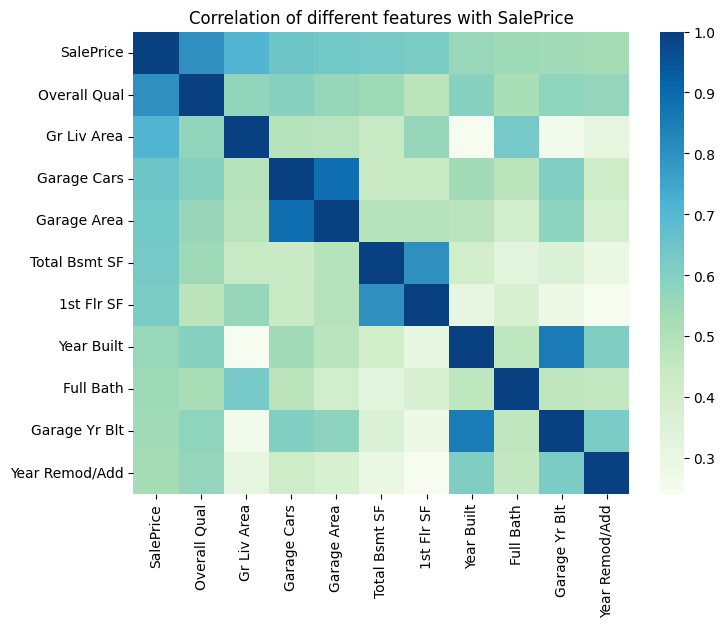

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(abs(df[imp_num_features].corr()), cmap='GnBu')
plt.title('Correlation of different features with SalePrice')

In [10]:
df['HouseAge'].corr(df['SalePrice'])

np.float64(-0.5589068324589404)

In [11]:
imp_num_features.remove('SalePrice')

In [12]:
categorical_features

Index(['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC',
       'Central Air', 'Electrical', 'Kitchen Qual', 'Functional',
       'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual',
       'Garage Cond', 'Paved Drive', 'Pool QC', 'Fence', 'Misc Feature',
       'Sale Type', 'Sale Condition'],
      dtype='object')

In [13]:
df[categorical_features].isnull().sum()

,0
MS Zoning,0
Street,0
Alley,2732
Lot Shape,0
Land Contour,0
Utilities,0
Lot Config,0
Land Slope,0
Neighborhood,0
Condition 1,0


In [14]:
df['House Style'].value_counts()

,count
House Style,
1Story,1481
2Story,873
1.5Fin,314
SLvl,128
SFoyer,83
2.5Unf,24
1.5Unf,19
2.5Fin,8


In [15]:
prob_imp_cat_features = ['MS Zoning', 'Lot Shape', 'Land Contour', 'Utilities', 'Neighborhood', 'Condition 1', 'Bldg Type', 'Garage Qual', 'Electrical']
df[prob_imp_cat_features].isnull().sum()

,0
MS Zoning,0
Lot Shape,0
Land Contour,0
Utilities,0
Neighborhood,0
Condition 1,0
Bldg Type,0
Garage Qual,159
Electrical,1


In [16]:
import scipy.stats as stats

anova_results = {}

for col in categorical_features:
    groups = [
        group["SalePrice"].values
        for _, group in df.groupby(col)
    ]

    f_stat, p_value = stats.f_oneway(*groups)

    anova_results[col] = {
        "F-statistic": f_stat,
        "p-value": p_value
    }

anova_results

{'MS Zoning': {'F-statistic': np.float64(63.8051693932759),
  'p-value': np.float64(1.1004990281237354e-74)},
 'Street': {'F-statistic': np.float64(10.40944530910943),
  'p-value': np.float64(0.001267537207464486)},
 'Alley': {'F-statistic': np.float64(87.67357025067429),
  'p-value': np.float64(1.8633943587728047e-17)},
 'Lot Shape': {'F-statistic': np.float64(98.43160142462207),
  'p-value': np.float64(1.0678631356077208e-60)},
 'Land Contour': {'F-statistic': np.float64(44.56101822211419),
  'p-value': np.float64(3.7436782290891496e-28)},
 'Utilities': {'F-statistic': np.float64(1.547713193827125),
  'p-value': np.float64(0.21290794617934414)},
 'Lot Config': {'F-statistic': np.float64(15.689742372167043),
  'p-value': np.float64(1.0412226056008607e-12)},
 'Land Slope': {'F-statistic': np.float64(6.912148819819738),
  'p-value': np.float64(0.0010119492021355193)},
 'Neighborhood': {'F-statistic': np.float64(144.3950774998117),
  'p-value': np.float64(0.0)},
 'Condition 1': {'F-stati

In [17]:
sorted_results = dict(
    sorted(
        anova_results.items(),
        key=lambda x: x[1]["p-value"],
        reverse = True
    )
)

for feature, result in sorted_results.items():
    print(
        feature,
        "F =", result["F-statistic"],
        "p =", result["p-value"]
    )

Misc Feature F = 1.2633399122026403 p = 0.2894187450962494
Utilities F = 1.547713193827125 p = 0.21290794617934414
Pool QC F = 3.3408678523543167 p = 0.06968642820913178
Street F = 10.40944530910943 p = 0.001267537207464486
Land Slope F = 6.912148819819738 p = 0.0010119492021355193
BsmtFin Type 2 F = 4.882701326484301 p = 0.00018825293760823942
Heating F = 5.741147311674295 p = 2.8022946827171354e-05
Fence F = 10.764870748510864 p = 6.875827443375439e-07
Roof Matl F = 6.808304258623214 p = 4.8475091191785076e-08
Functional F = 7.46576836482356 p = 6.2702858486829475e-09
Lot Config F = 15.689742372167043 p = 1.0412226056008607e-12
Condition 2 F = 10.426239775311213 p = 5.430319153269248e-13
Exter Cond F = 20.30981678487074 p = 1.611921363209932e-16
Bsmt Cond F = 20.675894576509485 p = 8.16488873339312e-17
Alley F = 87.67357025067429 p = 1.8633943587728047e-17
Mas Vnr Type F = 28.001244481284875 p = 1.769729410733451e-17
Garage Cond F = 24.073574910045902 p = 1.3263122578810209e-19
Bldg 

In [18]:
filtered_results = dict(
    filter(
        lambda x: x[1]["p-value"] < 0.01,
        sorted_results.items()
    )
)
len(filtered_results)

40

In [19]:
filtered_results = list(filtered_results.items())[:15]
filtered_results


[('Street',
  {'F-statistic': np.float64(10.40944530910943),
   'p-value': np.float64(0.001267537207464486)}),
 ('Land Slope',
  {'F-statistic': np.float64(6.912148819819738),
   'p-value': np.float64(0.0010119492021355193)}),
 ('BsmtFin Type 2',
  {'F-statistic': np.float64(4.882701326484301),
   'p-value': np.float64(0.00018825293760823942)}),
 ('Heating',
  {'F-statistic': np.float64(5.741147311674295),
   'p-value': np.float64(2.8022946827171354e-05)}),
 ('Fence',
  {'F-statistic': np.float64(10.764870748510864),
   'p-value': np.float64(6.875827443375439e-07)}),
 ('Roof Matl',
  {'F-statistic': np.float64(6.808304258623214),
   'p-value': np.float64(4.8475091191785076e-08)}),
 ('Functional',
  {'F-statistic': np.float64(7.46576836482356),
   'p-value': np.float64(6.2702858486829475e-09)}),
 ('Lot Config',
  {'F-statistic': np.float64(15.689742372167043),
   'p-value': np.float64(1.0412226056008607e-12)}),
 ('Condition 2',
  {'F-statistic': np.float64(10.426239775311213),
   'p-val

In [20]:
ordinal_cols = [
    "Exter Qual",
    "Exter Cond",
    "Bsmt Qual",
    "Bsmt Cond",
    "Heating QC",
    "Kitchen Qual",
    "Fireplace Qu",
    "Garage Qual",
    "Garage Cond",
    "Pool QC"
]

ordinal_mapping = {
    "NA": 0,
    "Po": 1,
    "Fa": 2,
    "TA": 3,
    "Gd": 4,
    "Ex": 5
}

for col in ordinal_cols:
    df[col] = df[col].map(ordinal_mapping)

In [21]:
imp_cat_features = []
for item in filtered_results:
  imp_cat_features.append(item[0])

imp_cat_features

['Street',
 'Land Slope',
 'BsmtFin Type 2',
 'Heating',
 'Fence',
 'Roof Matl',
 'Functional',
 'Lot Config',
 'Condition 2',
 'Exter Cond',
 'Bsmt Cond',
 'Alley',
 'Mas Vnr Type',
 'Garage Cond',
 'Bldg Type']

In [22]:
df[imp_cat_features].isnull().sum()

,0
Street,0
Land Slope,0
BsmtFin Type 2,81
Heating,0
Fence,2358
Roof Matl,0
Functional,0
Lot Config,0
Condition 2,0
Exter Cond,0


In [23]:
df['BsmtFin Type 2'] = df['BsmtFin Type 2'].replace(np.nan, 'Unf')
df[['Fence', 'Bsmt Cond', 'Alley', 'Mas Vnr Type', 'Garage Cond']] = df[['Fence', 'Bsmt Cond', 'Alley', 'Mas Vnr Type', 'Garage Cond']].replace(np.nan, 'NA')

In [24]:
df['Fence']

,Fence
0,NA
1,MnPrv
2,NA
3,NA
4,MnPrv
...,...
2925,GdPrv
2926,MnPrv
2927,MnPrv
2928,NA


In [25]:
nominal_feature = []

for feature in categorical_features:
  if (feature not in ordinal_cols) and (feature in imp_cat_features):
    nominal_feature.append(feature)

nominal_feature

['Street',
 'Alley',
 'Lot Config',
 'Land Slope',
 'Condition 2',
 'Bldg Type',
 'Roof Matl',
 'Mas Vnr Type',
 'BsmtFin Type 2',
 'Heating',
 'Functional',
 'Fence']

In [28]:
df = pd.get_dummies(data = df, columns= nominal_feature, drop_first= True)

In [29]:
df.shape

(2930, 130)

In [31]:
df[imp_num_features] = np.log(1 + df[imp_num_features])